In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [17]:
housing = fetch_california_housing(as_frame=True)

df = housing.frame

print("Dataset Loaded Successfully!")
display(df.head())

Dataset Loaded Successfully!


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [18]:
print("First 5 Rows:")
display(df.head())

print("Last 5 Rows:")
display(df.tail())

First 5 Rows:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


Last 5 Rows:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09,0.781
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21,0.771
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22,0.923
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32,0.847
20639,2.3886,16.0,5.254717,1.162264,1387.0,2.616981,39.37,-121.24,0.894


In [19]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

Dataset Shape: (20640, 9)

Column Names:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']

Data Types:
MedInc         float64
HouseAge       float64
AveRooms       float64
AveBedrms      float64
Population     float64
AveOccup       float64
Latitude       float64
Longitude      float64
MedHouseVal    float64
dtype: object


In [20]:
display(df.describe())

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [21]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Missing Values:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Duplicate Rows:
0


In [22]:
X = df[['MedInc']]
y = df['MedHouseVal']

print("Input Feature:")
display(X.head())

print("Target Variable:")
display(y.head())

Input Feature:


,MedInc
0,8.3252
1,8.3014
2,7.2574
3,5.6431
4,3.8462


Target Variable:


,MedHouseVal
0,4.526
1,3.585
2,3.521
3,3.413
4,3.422


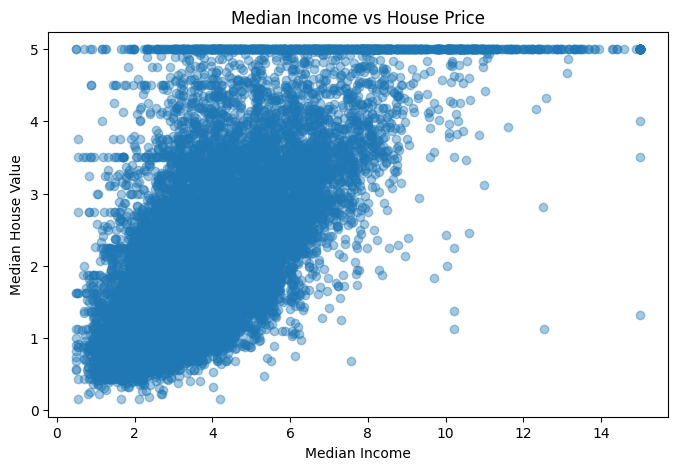

In [23]:
plt.figure(figsize=(8,5))

plt.scatter(X['MedInc'], y, alpha=0.4)

plt.title("Median Income vs House Price")
plt.xlabel("Median Income")
plt.ylabel("Median House Value")

plt.show()

In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Data: (16512, 1)
Testing Data: (4128, 1)
Training Target: (16512,)
Testing Target: (4128,)


In [25]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")

print("Intercept:", model.intercept_)
print("Coefficient:", model.coef_[0])

Linear Regression Model Trained Successfully!
Intercept: 0.4445972916907879
Coefficient: 0.4193384939381271


In [26]:
print("Linear Regression Equation:")

print(
    "House Price =",
    model.intercept_,
    "+",
    model.coef_[0],
    "* Median Income"
)

Linear Regression Equation:
House Price = 0.4445972916907879 + 0.4193384939381271 * Median Income


In [27]:
y_pred = model.predict(X_test)

comparison = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred
})

print("Actual vs Predicted House Prices:")
display(comparison.head(10))

Actual vs Predicted House Prices:


,Actual Price,Predicted Price
0,0.47700,1.149589
1,0.45800,1.506069
2,5.00001,1.903937
3,2.18600,2.850594
4,2.78000,2.006633
5,1.58700,2.421652
6,1.98200,2.576472
7,1.57500,1.992292
8,3.40000,2.458932
9,4.46600,3.846774


In [28]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error (MAE):", mae)
print("Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)
print("R2 Score:", r2)

Mean Absolute Error (MAE): 0.629908653009376
Mean Squared Error (MSE): 0.7091157771765549
Root Mean Squared Error (RMSE): 0.8420901241414455
R2 Score: 0.45885918903846656


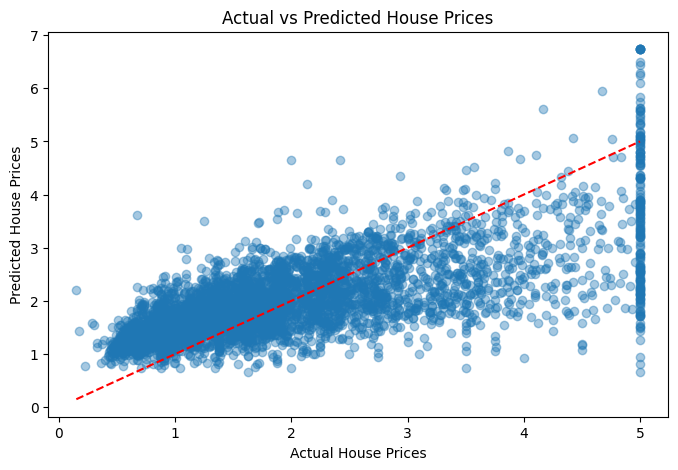

In [29]:
plt.figure(figsize=(8,5))

plt.scatter(y_test, y_pred, alpha=0.4)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.title("Actual vs Predicted House Prices")
plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")

plt.show()

In [30]:
new_data = pd.DataFrame({
    'MedInc': [5.0]
})

prediction = model.predict(new_data)

print("Median Income:", 5.0)

print("Predicted House Value:",
      prediction[0])

print("Predicted Price in Dollars:",
      prediction[0] * 100000)

Median Income: 5.0
Predicted House Value: 2.5412897613814236
Predicted Price in Dollars: 254128.97613814235


In [31]:
df.to_csv('California_Housing_Dataset.csv', index=False)